In [1]:
base ="klue/bert-base"
# base = 'BM-K/KoSimCSE-bert'

In [2]:
from datasets import load_dataset, DatasetDict
from transformers import AutoTokenizer
ds = load_dataset("csv", data_files={"train": "./Text Classification Dataset/train.csv"}) 
ds = ds['train'].train_test_split(test_size=0.1, seed=42)
ds = DatasetDict({
    'train'      :ds['train'],
    'validation' :ds['test'],
})
tok = AutoTokenizer.from_pretrained(base)
def tok_fn(batch):
    return tok(batch['full_text'], truncation=True)
ds = ds.map(tok_fn,batched=True)

In [3]:
needs = ['input_ids','attention_mask', 'token_type_ids', 'generated']
ds_generated = ds.filter(lambda x: x['generated'] == 1)
ds_generated = ds_generated.remove_columns([c for c in ds['train'].column_names if c not in needs])

In [4]:
ds_non_generated = ds.filter(lambda x: x['generated'] == 0)
ds_non_generated = ds_non_generated.remove_columns([c for c in ds['train'].column_names if c not in needs])

In [5]:
from datasets import concatenate_datasets
ds_mixed = DatasetDict({
    'train': concatenate_datasets([ds_generated['train'], ds_non_generated['train'].select(range(ds_generated['train'].num_rows))]),
    'validation': concatenate_datasets([ds_generated['validation'], ds_non_generated['validation'].select(range(ds_generated['validation'].num_rows))]),
})

In [6]:
ds_mixed

DatasetDict({
    train: Dataset({
        features: ['generated', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 14374
    })
    validation: Dataset({
        features: ['generated', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 1616
    })
})

In [7]:
import torch
import torch.nn as nn
from transformers import AutoModel

class CLSBinaryClassifier(nn.Module):
    """
    BERT → [CLS] (첫 토큰) → LayerNorm + MLP → 1 logit (이항분류)
    - 손실: BCEWithLogitsLoss 사용 (sigmoid는 손실 밖에서만)
    """
    def __init__(self, base_model_name,
                 freeze_bert=True, hidden=256, p_drop=0.1):
        super().__init__()
        self.bert = AutoModel.from_pretrained(base_model_name)
        H = self.bert.config.hidden_size

        if freeze_bert:
            for p in self.bert.parameters():
                p.requires_grad = False

        self.head = nn.Sequential(
            nn.LayerNorm(H),
            nn.Linear(H, hidden),
            nn.GELU(),
            nn.Dropout(p_drop),
            nn.Linear(hidden, 1)      # 1 logit (N,)
        )

    def forward(self, input_ids, attention_mask):
        out = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        cls = out.last_hidden_state[:, 0, :]          # (N, H)  첫 토큰([CLS])
        logit = self.head(cls).squeeze(-1)            # (N,)
        return {"logits": logit, "cls": cls}


In [11]:
device = "cuda"
model = CLSBinaryClassifier(base_model_name=base,
                            freeze_bert=True, hidden=256).to(device)

criterion = nn.BCEWithLogitsLoss()  # 균형이면 그냥 nn.BCEWithLogitsLoss()

# decay / no_decay 분리(정규화/바이어스는 decay 0)
decay, no_decay = [], []
for n, p in model.named_parameters():
    if not p.requires_grad:
        continue
    if p.ndim == 1 or "bias" in n or "norm" in n.lower():
        no_decay.append(p)
    else:
        decay.append(p)

optimizer = torch.optim.AdamW(
    [{"params": decay, "weight_decay": 1e-4},
     {"params": no_decay, "weight_decay": 0.0}],
    lr=1e-3
)

from transformers import DataCollatorWithPadding
from torch.utils.data import DataLoader
num_epochs = 5
collator = DataCollatorWithPadding(tokenizer=tok)
# 3. DataLoader 생성
train_loader = DataLoader(
    ds_mixed['train'],       
    batch_size=16,              
    shuffle=True,               
    collate_fn=collator        
)


model.train()
for epoch in range(num_epochs):
    for batch in train_loader:
        ids  = batch["input_ids"].to(device)
        attn = batch["attention_mask"].to(device)
        y    = batch["generated"].float().to(device)  # (N,)

        optimizer.zero_grad(set_to_none=True)
        out = model(ids, attn)
        loss = criterion(out["logits"], y)
        loss.backward()
        optimizer.step()
    print(f'epoch {epoch+1} end, loss: {loss.item()}')


epoch 1 end, loss: 0.28898441791534424
epoch 2 end, loss: 0.47524842619895935
epoch 3 end, loss: 0.5593118667602539
epoch 4 end, loss: 0.4374849200248718
epoch 5 end, loss: 0.4033550024032593


In [20]:
from torch import sigmoid
# 3. DataLoader 생성
train_loader = DataLoader(
    ds_generated['validation'],       
    batch_size=1,              
    shuffle=True,               
    collate_fn=collator        
)

losses = []
model.eval()
for batch in train_loader:
    with torch.no_grad():
        ids = batch["input_ids"].to(device)
        attn = batch["attention_mask"].to(device)
        y = batch["generated"].float().to(device)      # (N,) float 0/1

        out = model(ids, attn)
        loss = criterion(out['logits'], y)
        losses.append(loss.item())

In [21]:
sum(losses)/len(losses)

0.3400004163139182

In [12]:
from torch import sigmoid
# 3. DataLoader 생성
train_loader = DataLoader(
    ds_generated['validation'],       
    batch_size=1,              
    shuffle=True,               
    collate_fn=collator        
)

probs_generated = []
model.eval()
for batch in train_loader:
    with torch.no_grad():
        ids = batch["input_ids"].to(device)
        attn = batch["attention_mask"].to(device)
        y = batch["generated"].float().to(device)      # (N,) float 0/1

        out = model(ids, attn)
        prob = sigmoid(input=out["logits"])
        probs_generated.append(prob)

In [13]:
train_loader = DataLoader(
    ds_non_generated['validation'].select(range(len(ds_generated['validation']))),       
    batch_size=1,              
    shuffle=True,               
    collate_fn=collator        
)

probs_non_generated = []
model.eval()
for batch in train_loader:
    with torch.no_grad():
        ids = batch["input_ids"].to(device)
        attn = batch["attention_mask"].to(device)
        y = batch["generated"].float().to(device)      # (N,) float 0/1

        out = model(ids, attn)
        prob = sigmoid(input=out["logits"])
        probs_non_generated.append(prob)

In [14]:
def extract_to_list(probs):
    to_return = []
    for prob in probs:
        to_return.append(prob.item())
    return to_return

In [15]:
probs_generated = extract_to_list(probs_generated)
probs_non_generated = extract_to_list(probs_non_generated)

In [16]:
import pandas as pd
ret = pd.DataFrame({
    'prob': probs_generated + probs_non_generated,
    'generate': [1]*len(probs_generated) + [0]*len(probs_non_generated),
})

<Axes: xlabel='prob', ylabel='Count'>

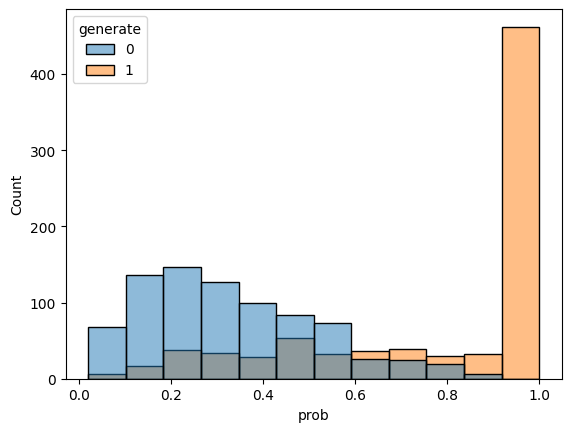

In [17]:
import seaborn as sns
sns.histplot(ret, x='prob', hue='generate')

<Axes: xlabel='generate', ylabel='prob'>

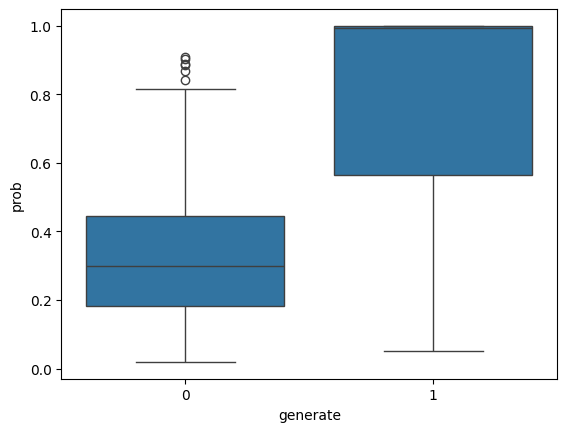

In [18]:
import seaborn as sns
sns.boxplot(ret, y='prob', x='generate')